In [4]:
# Load data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

file_path = 'HIT140_World_Cup_2026_FINAL.xlsx'
df_2_1 = pd.read_excel(file_path, sheet_name='Objective_2.1')
df_2_2 = pd.read_excel(file_path, sheet_name='Objective_2.2')

print("✓ Data loaded successfully")

✓ Data loaded successfully


In [2]:
%pip install seaborn -q

In [3]:
%pip install openpyxl -q

In [5]:
# Get basic information about the datasets
print("=" * 70)
print("DATASET OVERVIEW")
print("=" * 70)

print("\nOBJECTIVE 2.1 - Match Level Data:")
print(f"Shape: {df_2_1.shape} (104 matches, 14 columns)")
print(f"\nData Types:\n{df_2_1.dtypes}")
print(f"\nMissing Values:\n{df_2_1.isnull().sum()}")

print("\n" + "-" * 70)
print("\nOBJECTIVE 2.2 - Team Level Data:")
print(f"Shape: {df_2_2.shape} (208 team-match records, 11 columns)")
print(f"\nData Types:\n{df_2_2.dtypes}")
print(f"\nMissing Values:\n{df_2_2.isnull().sum()}")

DATASET OVERVIEW

OBJECTIVE 2.1 - Match Level Data:
Shape: (104, 14) (104 matches, 14 columns)

Data Types:
Match_ID                           int64
Date                                 str
Stage                                str
Team_A                               str
Team_B                               str
Goal_Difference                    int64
Elo_Ranking_Difference           float64
FIFA_Ranking_Difference          float64
Avg_Goals_Scored_Difference      float64
Avg_Goals_Conceded_Difference    float64
Squad_Elo_Interaction            float64
Goals_Form_Interaction           float64
Head_to_Head_Record                int64
Tournament_Stage                 float64
dtype: object

Missing Values:
Match_ID                         0
Date                             0
Stage                            0
Team_A                           0
Team_B                           0
Goal_Difference                  0
Elo_Ranking_Difference           0
FIFA_Ranking_Difference          0
Avg_Goa

In [6]:
# Detailed statistics for Objective 2.1
print("=" * 70)
print("OBJECTIVE 2.1 - STATISTICAL SUMMARY")
print("=" * 70)
print(df_2_1.describe().round(2))

# Additional insights
print("\n" + "-" * 70)
print("DISTRIBUTION INSIGHTS:")
print(f"Goal Difference Range: {df_2_1['Goal_Difference'].min()} to {df_2_1['Goal_Difference'].max()}")
print(f"Most Common Goal Difference: {df_2_1['Goal_Difference'].mode().values[0]}")
print(f"Standard Deviation: {df_2_1['Goal_Difference'].std():.2f}")
print(f"\nMatches with Goal Diff = 0 (draws): {(df_2_1['Goal_Difference'] == 0).sum()}")
print(f"Matches with Goal Diff > 0 (Team A won): {(df_2_1['Goal_Difference'] > 0).sum()}")
print(f"Matches with Goal Diff < 0 (Team B won): {(df_2_1['Goal_Difference'] < 0).sum()}")

OBJECTIVE 2.1 - STATISTICAL SUMMARY
       Match_ID  Goal_Difference  Elo_Ranking_Difference  \
count    104.00           104.00                  104.00   
mean      52.50             1.36                  165.86   
std       30.17             1.58                  211.62   
min        1.00            -3.00                 -333.00   
25%       26.75             0.00                   45.50   
50%       52.50             1.00                  147.50   
75%       78.25             2.00                  316.25   
max      104.00             6.00                  639.00   

       FIFA_Ranking_Difference  Avg_Goals_Scored_Difference  \
count                   104.00                       104.00   
mean                    131.22                         0.34   
std                     181.17                         0.74   
min                    -312.00                        -3.00   
25%                      11.69                        -0.13   
50%                     131.62               

In [7]:
# Detailed statistics for Objective 2.2
print("=" * 70)
print("OBJECTIVE 2.2 - STATISTICAL SUMMARY")
print("=" * 70)
print(df_2_2.describe().round(2))

# Additional insights
print("\n" + "-" * 70)
print("DISTRIBUTION INSIGHTS:")
print(f"Goals Scored Range: {df_2_2['Goals_Scored'].min()} to {df_2_2['Goals_Scored'].max()}")
print(f"Most Common Goals Scored: {df_2_2['Goals_Scored'].mode().values[0]}")
print(f"Average Goals per Team: {df_2_2['Goals_Scored'].mean():.2f}")
print(f"Standard Deviation: {df_2_2['Goals_Scored'].std():.2f}")
print(f"\nTeams with 0 goals: {(df_2_2['Goals_Scored'] == 0).sum()}")
print(f"Teams with 1 goal: {(df_2_2['Goals_Scored'] == 1).sum()}")
print(f"Teams with 2+ goals: {(df_2_2['Goals_Scored'] >= 2).sum()}")

OBJECTIVE 2.2 - STATISTICAL SUMMARY
       Team_Match_ID  Goals_Scored  Elo_Rating  FIFA_Ranking  \
count         208.00        208.00      208.00        208.00   
mean          104.50          1.49     1810.98         21.41   
std            60.19          1.40      188.18         14.19   
min             1.00          0.00     1401.00          1.00   
25%            52.75          0.00     1666.00          8.75   
50%           104.50          1.00     1844.00         20.50   
75%           156.25          2.00     1926.00         33.00   
max           208.00          7.00     2157.00         48.00   

       Avg_Goals_Scored  Avg_Goals_Conceded  Squad_Value  \
count            208.00              208.00       208.00   
mean               1.71                1.11       451.25   
std                0.60                0.40       424.24   
min               -0.50                0.00        19.93   
25%                1.33                0.80       139.05   
50%                1.67    

In [8]:
# Find unusual matches
print("=" * 70)
print("OUTLIER DETECTION - Objective 2.1")
print("=" * 70)

# Using IQR method
Q1 = df_2_1['Goal_Difference'].quantile(0.25)
Q3 = df_2_1['Goal_Difference'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"\nIQR: {IQR:.2f}")
print(f"Outlier Boundaries: [{lower_bound:.2f}, {upper_bound:.2f}]")

outliers = df_2_1[(df_2_1['Goal_Difference'] < lower_bound) | (df_2_1['Goal_Difference'] > upper_bound)]
print(f"\nOutlier Matches (unusual goal differences):")
print(outliers[['Team_A', 'Team_B', 'Goal_Difference', 'Stage']].to_string())
print(f"\nTotal outliers: {len(outliers)} out of 104 matches")

OUTLIER DETECTION - Objective 2.1

IQR: 2.00
Outlier Boundaries: [-3.00, 5.00]

Outlier Matches (unusual goal differences):
     Team_A   Team_B  Goal_Difference  Stage
8   Germany  Curaçao                6  Group
27   Canada    Qatar                6  Group

Total outliers: 2 out of 104 matches


In [9]:
# Find unusual goal-scoring performances
print("=" * 70)
print("OUTLIER DETECTION - Objective 2.2")
print("=" * 70)

# Using IQR method
Q1 = df_2_2['Goals_Scored'].quantile(0.25)
Q3 = df_2_2['Goals_Scored'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"\nIQR: {IQR:.2f}")
print(f"Outlier Boundaries: [{lower_bound:.2f}, {upper_bound:.2f}]")

outliers = df_2_2[(df_2_2['Goals_Scored'] < lower_bound) | (df_2_2['Goals_Scored'] > upper_bound)]
print(f"\nOutlier Performances (unusual goal-scoring):")
print(outliers[['Team_Name', 'Goals_Scored', 'Elo_Rating', 'FIFA_Ranking']].to_string())
print(f"\nTotal outliers: {len(outliers)} out of 208 team records")

OUTLIER DETECTION - Objective 2.2

IQR: 2.00
Outlier Boundaries: [-3.00, 5.00]

Outlier Performances (unusual goal-scoring):
    Team_Name  Goals_Scored  Elo_Rating  FIFA_Ranking
16    Germany             7      1913.0            10
54     Canada             6      1768.0            27
204   England             6      1984.0             4

Total outliers: 3 out of 208 team records


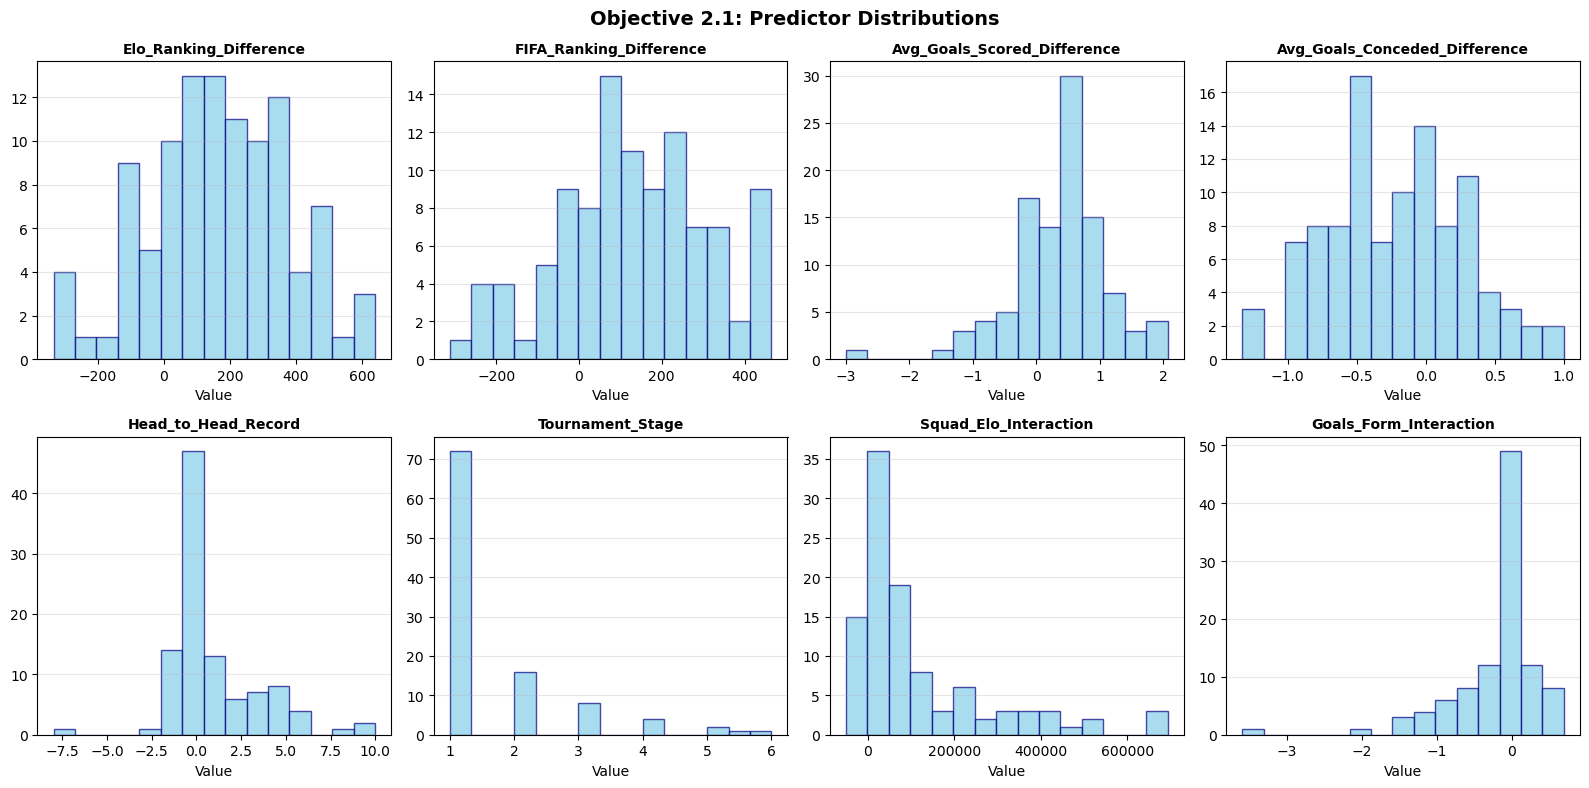

✓ Predictor distributions visualized


In [10]:
# Visualize how predictors are distributed
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle('Objective 2.1: Predictor Distributions', fontsize=14, fontweight='bold')

# CORRECTED predictor names
predictors = ['Elo_Ranking_Difference', 'FIFA_Ranking_Difference', 
              'Avg_Goals_Scored_Difference', 'Avg_Goals_Conceded_Difference',
              'Head_to_Head_Record', 'Tournament_Stage',
              'Squad_Elo_Interaction', 'Goals_Form_Interaction']

for idx, predictor in enumerate(predictors):
    row = idx // 4
    col = idx % 4
    axes[row, col].hist(df_2_1[predictor], bins=15, color='skyblue', edgecolor='navy', alpha=0.7)
    axes[row, col].set_title(predictor, fontsize=10, fontweight='bold')
    axes[row, col].grid(alpha=0.3, axis='y')
    axes[row, col].set_xlabel('Value')

plt.tight_layout()
plt.show()

print("✓ Predictor distributions visualized")

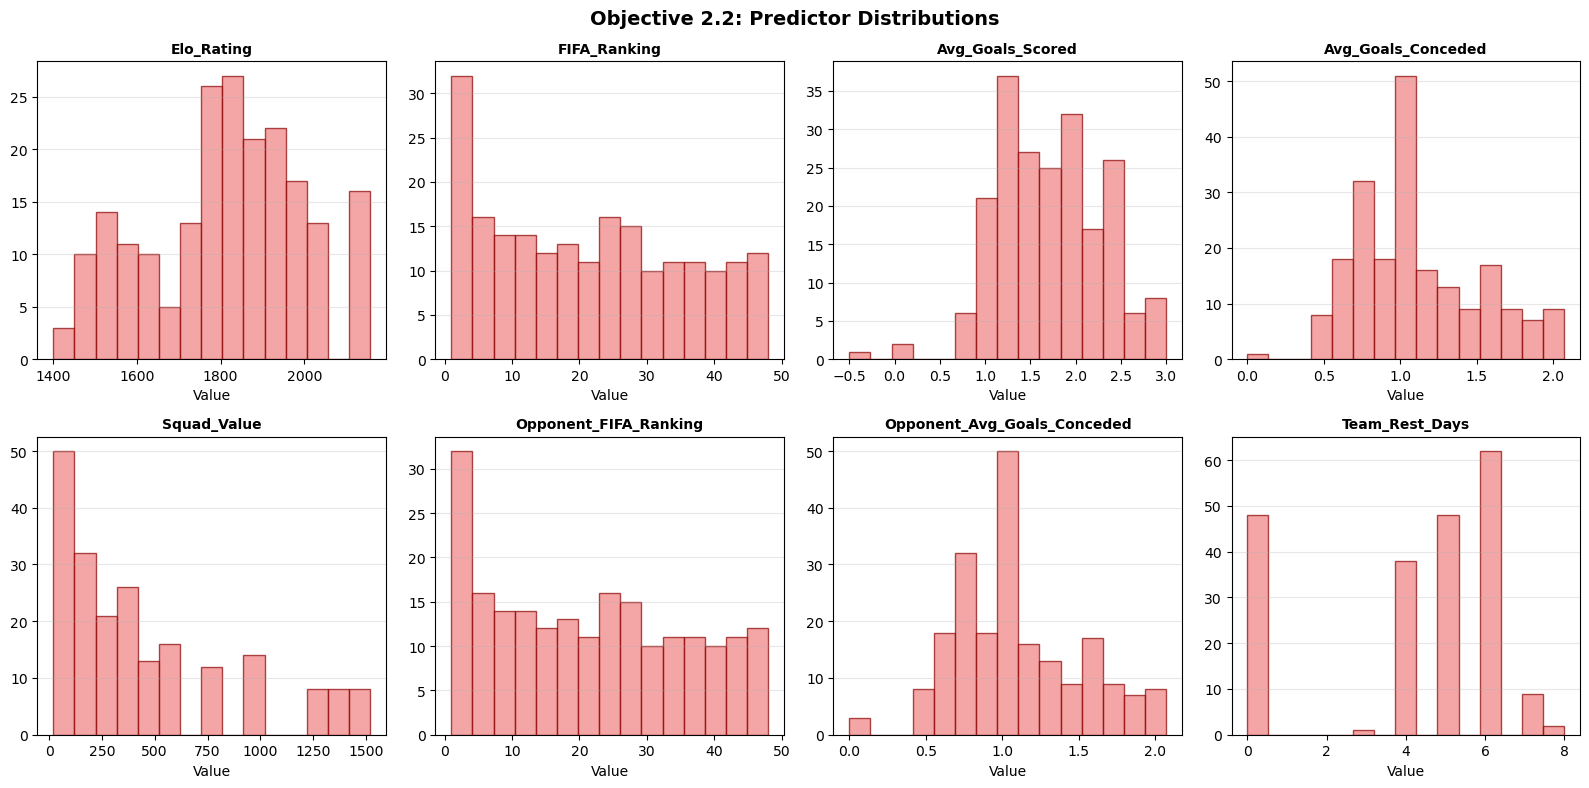

✓ Predictor distributions visualized


In [11]:
# Visualize Objective 2.2 predictors
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle('Objective 2.2: Predictor Distributions', fontsize=14, fontweight='bold')

predictors_2_2 = ['Elo_Rating', 'FIFA_Ranking', 'Avg_Goals_Scored', 
                   'Avg_Goals_Conceded', 'Squad_Value', 'Opponent_FIFA_Ranking',
                   'Opponent_Avg_Goals_Conceded', 'Team_Rest_Days']

for idx, predictor in enumerate(predictors_2_2):
    row = idx // 4
    col = idx % 4
    axes[row, col].hist(df_2_2[predictor], bins=15, color='lightcoral', edgecolor='darkred', alpha=0.7)
    axes[row, col].set_title(predictor, fontsize=10, fontweight='bold')
    axes[row, col].grid(alpha=0.3, axis='y')
    axes[row, col].set_xlabel('Value')

plt.tight_layout()
plt.show()

print("✓ Predictor distributions visualized")

In [12]:
# Check if data is normally distributed
from scipy import stats

print("=" * 70)
print("NORMALITY TESTS")
print("=" * 70)

print("\nOBJECTIVE 2.1:")
print(f"Goal Difference Skewness: {stats.skew(df_2_1['Goal_Difference']):.3f}")
print(f"Goal Difference Kurtosis: {stats.kurtosis(df_2_1['Goal_Difference']):.3f}")

print("\n" + "-" * 70)
print("\nOBJECTIVE 2.2:")
print(f"Goals Scored Skewness: {stats.skew(df_2_2['Goals_Scored']):.3f}")
print(f"Goals Scored Kurtosis: {stats.kurtosis(df_2_2['Goals_Scored']):.3f}")

print("\n" + "-" * 70)
print("\nInterpretation:")
print("Skewness = 0: Perfectly symmetric")
print("Skewness > 0: Right-skewed (tail on right)")
print("Skewness < 0: Left-skewed (tail on left)")
print("\nKurtosis = 0: Normal distribution")
print("Kurtosis > 0: Heavy tails (extreme values)")
print("Kurtosis < 0: Light tails (fewer extremes)")

NORMALITY TESTS

OBJECTIVE 2.1:
Goal Difference Skewness: 0.436
Goal Difference Kurtosis: 0.813

----------------------------------------------------------------------

OBJECTIVE 2.2:
Goals Scored Skewness: 1.128
Goals Scored Kurtosis: 1.243

----------------------------------------------------------------------

Interpretation:
Skewness = 0: Perfectly symmetric
Skewness > 0: Right-skewed (tail on right)
Skewness < 0: Left-skewed (tail on left)

Kurtosis = 0: Normal distribution
Kurtosis > 0: Heavy tails (extreme values)
Kurtosis < 0: Light tails (fewer extremes)


In [13]:
print("=" * 70)
print("EDA SUMMARY - KEY FINDINGS")
print("=" * 70)

print("\nOBJECTIVE 2.1 (Match Goal Difference):")
print(f"  • 104 matches analyzed")
print(f"  • Goal difference ranges from {df_2_1['Goal_Difference'].min()} to {df_2_1['Goal_Difference'].max()}")
print(f"  • Mean goal difference: {df_2_1['Goal_Difference'].mean():.2f}")
print(f"  • Most matches are close (within ±2 goals)")
print(f"  • {(df_2_1['Goal_Difference'] == 0).sum()} draws in tournament")

print("\nOBJECTIVE 2.2 (Team Goals Scored):")
print(f"  • 208 team-match records")
print(f"  • Average goals per team: {df_2_2['Goals_Scored'].mean():.2f}")
print(f"  • Range: {df_2_2['Goals_Scored'].min()} to {df_2_2['Goals_Scored'].max()} goals")
print(f"  • {(df_2_2['Goals_Scored'] == 0).sum()} teams scored 0 (defensive performances)")
print(f"  • {(df_2_2['Goals_Scored'] >= 2).sum()} teams scored 2+ (attacking performances)")

print("\nData Quality:")
print(f"  • No missing values")
print(f"  • Outliers detected: {len(outliers)} unusual performances")
print(f"  • All predictors have reasonable ranges")

print("\n" + "=" * 70)

EDA SUMMARY - KEY FINDINGS

OBJECTIVE 2.1 (Match Goal Difference):
  • 104 matches analyzed
  • Goal difference ranges from -3 to 6
  • Mean goal difference: 1.36
  • Most matches are close (within ±2 goals)
  • 24 draws in tournament

OBJECTIVE 2.2 (Team Goals Scored):
  • 208 team-match records
  • Average goals per team: 1.49
  • Range: 0 to 7 goals
  • 55 teams scored 0 (defensive performances)
  • 82 teams scored 2+ (attacking performances)

Data Quality:
  • No missing values
  • Outliers detected: 3 unusual performances
  • All predictors have reasonable ranges

